In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_PATH = Path("Water Quality.csv")
OUTPUT_DIR = Path("aquainsight_task13_15_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [4]:
if not DATA_PATH.exists():
    found = list(Path.cwd().glob("*.csv"))
    if len(found) == 1:
        DATA_PATH = found[0]
    else:
        raise FileNotFoundError("Put Water Quality.csv beside this notebook or edit DATA_PATH.")

raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)
print("Media types:", raw["ActivityMediaName"].value_counts(dropna=False).head(10).to_dict())
display(raw.head())
print("\nMost common parameters:")
display(raw["CharacteristicName"].value_counts().head(35).to_frame("row_count"))
print("\nUnits by parameter:")
display(raw.groupby("CharacteristicName")["ResultUnit"].agg(lambda s: ", ".join(sorted(set(s.dropna().astype(str))))).to_frame("units").head(50))

Raw shape: (229916, 40)
Media types: {'Surface Water': 229916}


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,...,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN



Most common parameters:


,row_count
CharacteristicName,
Specific conductance,8963
pH,8946
"Total Nitrogen, mixed forms",7333
Magnesium,7312
Calcium,7307
Sodium,7300
Organic carbon,7272
Chloride,7250
Sulfate,7240



Units by parameter:


,units
CharacteristicName,
"Alkalinity, total",mg/L
Aluminum,"mg/L, ug/L"
Ammonia,mg/L
Antimony,ug/L
Apparent color,TCU
Arsenic,"mg/L, ug/L"
Barium,"mg/L, ug/L"
Beryllium,ug/L
Bismuth,ug/L


In [5]:
# Canonical parameters are kept only where a clear unit conversion is possible.
# Metals are converted to ug/L; nitrate and fluoride remain mg/L.
PARAMETER_MAP = {
    "pH": "pH",
    "Dissolved oxygen (DO)": "DO_mg_L",
    "Dissolved oxygen saturation": "DO_saturation_pct",
    "Turbidity": "Turbidity_NTU",
    "Nitrate": "Nitrate_mg_L",
    "Fluoride": "Fluoride_mg_L",
    "Arsenic": "Arsenic_ug_L",
    "Lead": "Lead_ug_L",
    "Cadmium": "Cadmium_ug_L",
    "Selenium": "Selenium_ug_L",
    "Uranium": "Uranium_ug_L",
    "Manganese": "Manganese_ug_L",
    "Temperature, water": "Temperature_C",
    "Fecal Coliform": "Fecal_Coliform_per_100mL",
    "Total Phosphorus, mixed forms": "Total_Phosphorus_mg_L"
}
d = raw[raw["CharacteristicName"].isin(PARAMETER_MAP)].copy()
d["ResultValue"] = pd.to_numeric(d["ResultValue"], errors="coerce")
d = d.dropna(subset=["ResultValue"])
d["Canonical"] = d["CharacteristicName"].map(PARAMETER_MAP)
d["UnitClean"] = d["ResultUnit"].astype(str).str.strip()

# Convert supported units. Unsupported unit variants become missing rather than silently mixed.
def convert_row(r):
    v, u, p = r["ResultValue"], r["UnitClean"], r["Canonical"]
    if p == "pH":
        return v if u in ("nan", "", "None") else v
    if p in ("DO_mg_L", "Nitrate_mg_L", "Fluoride_mg_L", "Total_Phosphorus_mg_L"):
        return v if u.lower() in ("mg/l", "mg/l as n", "mg/l as p") else np.nan
    if p == "DO_saturation_pct":
        return v if "%" in u or "percent" in u.lower() else np.nan
    if p == "Turbidity_NTU":
        return v if u.upper() == "NTU" else np.nan
    if p == "Temperature_C":
        return v if u.lower() in ("deg c", "°c", "degree celsius") else np.nan
    if p == "Fecal_Coliform_per_100mL":
        return v if "#/100mL" in u.replace(" ", "") else np.nan
    if p.endswith("_ug_L"):
        if u.lower() in ("ug/l", "µg/l"):
            return v
        if u.lower() == "mg/l":
            return v * 1000.0
        return np.nan
    return np.nan

d["ValueStandard"] = d.apply(convert_row, axis=1)
d = d.dropna(subset=["ValueStandard"])
sample_keys = [c for c in ["MonitoringLocationID", "ActivityStartDate"] if c in d.columns]
if not sample_keys:
    raise ValueError("Expected MonitoringLocationID and/or ActivityStartDate to identify samples.")
if "ActivityStartDate" in d.columns:
    d["ActivityStartDate"] = pd.to_datetime(d["ActivityStartDate"], errors="coerce")
    d = d.dropna(subset=["ActivityStartDate"])

samples = d.pivot_table(index=sample_keys, columns="Canonical", values="ValueStandard", aggfunc="mean").reset_index()
samples.columns.name = None
print("Sample-level table:", samples.shape)
display(samples.head())
print("Available canonical parameters:", [c for c in samples.columns if c not in sample_keys])

Sample-level table: (7282, 17)


,MonitoringLocationID,ActivityStartDate,Arsenic_ug_L,Cadmium_ug_L,DO_mg_L,DO_saturation_pct,Fecal_Coliform_per_100mL,Fluoride_mg_L,Lead_ug_L,Manganese_ug_L,Nitrate_mg_L,Selenium_ug_L,Temperature_C,Total_Phosphorus_mg_L,Turbidity_NTU,Uranium_ug_L,pH
0,NB01BR0006,2000-09-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.032,NaN,NaN,NaN
1,NB01BR0006,2000-10-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.038,NaN,NaN,NaN
2,NB01BR0006,2000-11-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011,NaN,NaN,NaN
3,NB01BR0006,2001-04-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.024,NaN,NaN,4.9
4,NB01BR0006,2001-05-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.015,NaN,NaN,5.1


Available canonical parameters: ['Arsenic_ug_L', 'Cadmium_ug_L', 'DO_mg_L', 'DO_saturation_pct', 'Fecal_Coliform_per_100mL', 'Fluoride_mg_L', 'Lead_ug_L', 'Manganese_ug_L', 'Nitrate_mg_L', 'Selenium_ug_L', 'Temperature_C', 'Total_Phosphorus_mg_L', 'Turbidity_NTU', 'Uranium_ug_L', 'pH']


In [7]:
# NSF classic parameter weights (Brown et al. convention).
# Parameters absent from the dataset or not unit-compatible are omitted and remaining weights renormalized.
NSF_WEIGHTS = {
    "DO_saturation_pct": 0.17,
    "Fecal_Coliform_per_100mL": 0.16,
    "pH": 0.11,
    "Nitrate_mg_L": 0.10,
    "Temperature_C": 0.10,
    "Turbidity_NTU": 0.08
}
available_nsf = [p for p in NSF_WEIGHTS if p in samples.columns]
print("Available NSF-related inputs:", available_nsf)
print("Unavailable classic NSF inputs include BOD and Total Solids; this is not the full NSF method.")

def nsf_proxy_subindex(param, s):
    # Transparent, editable proxy scoring rules (0–100); NOT original NSF rating curves.
    x = pd.to_numeric(s, errors="coerce")
    if param == "pH":
        # Score 100 within 6.5–8.5; linear decline outside.
        return (100 - np.where(x < 6.5, (6.5-x)*25,
                    np.where(x > 8.5, (x-8.5)*25, 0))).clip(0,100)
    if param == "DO_saturation_pct":
        return (x / 100 * 100).clip(0,100)
    if param == "Turbidity_NTU":
        return (100 - (x/5)*100).clip(0,100)
    if param == "Nitrate_mg_L":
        return (100 - (x/10)*100).clip(0,100)
    if param == "Fecal_Coliform_per_100mL":
        return (100 - np.log10(1+x)*25).clip(0,100)
    if param == "Temperature_C":
        # Illustrative relative deviation from 20 C; actual NSF curve uses temperature change.
        return (100 - np.abs(x-20)*4).clip(0,100)
    return pd.Series(np.nan, index=s.index)

nsf_sub = pd.DataFrame(index=samples.index)
for p in available_nsf:
    nsf_sub[p] = nsf_proxy_subindex(p, samples[p])
w = pd.Series({p:NSF_WEIGHTS[p] for p in available_nsf}, dtype=float)
nsf_score = nsf_sub.mul(w, axis=1).sum(axis=1, min_count=1) / nsf_sub.notna().mul(w, axis=1).sum(axis=1).replace(0,np.nan)
samples["NSF_weighted_available_proxy"] = nsf_score
print("NSF proxy computed for samples:", int(nsf_score.notna().sum()))

Available NSF-related inputs: ['DO_saturation_pct', 'Fecal_Coliform_per_100mL', 'pH', 'Nitrate_mg_L', 'Temperature_C', 'Turbidity_NTU']
Unavailable classic NSF inputs include BOD and Total Solids; this is not the full NSF method.
NSF proxy computed for samples: 7282


In [8]:
# Build a representative baseline row using parameter medians.
scenario_params = [p for p in available_nsf if samples[p].notna().any()]
baseline = samples[scenario_params].median(numeric_only=True)
print("Baseline representative parameter values:")
display(baseline.to_frame("median"))

Baseline representative parameter values:


,median
DO_saturation_pct,97.5000
Fecal_Coliform_per_100mL,22.5000
pH,5.4800
Nitrate_mg_L,0.1000
Temperature_C,11.4275
Turbidity_NTU,1.2000


In [10]:
def score_nsf_proxy_from_values(values):
    scores={}
    for p in scenario_params:
        x=pd.Series([values.get(p,np.nan)])
        scores[p]=float(nsf_proxy_subindex(p,x)[0]) if pd.notna(values.get(p,np.nan)) else np.nan
    score_series=pd.Series(scores,dtype=float)
    ww=pd.Series({p:NSF_WEIGHTS[p] for p in scenario_params})
    denom=ww[score_series.notna()].sum()
    return float((score_series*ww).sum()/denom) if denom>0 else np.nan

scenario_rows=[]
for param in scenario_params:
    for change in [-0.30,-0.15,0.15,0.30]:
        changed=baseline.to_dict()
        base_value=float(baseline[param])
        if param=="pH":
            changed[param]=base_value + change*1.0
        elif param=="DO_saturation_pct":
            changed[param]=base_value + change*100.0
        else:
            changed[param]=max(0.0,base_value*(1+change))
        scenario_rows.append({
            "Parameter":param,"Change":change,
            "Scenario value":changed[param],
            "Baseline NSF proxy":score_nsf_proxy_from_values(baseline.to_dict()),
            "Scenario NSF proxy":score_nsf_proxy_from_values(changed),
            "WQI change":score_nsf_proxy_from_values(changed)-score_nsf_proxy_from_values(baseline.to_dict())
        })
scenario_table=pd.DataFrame(scenario_rows)
display(scenario_table.round(3))
scenario_table.to_csv(OUTPUT_DIR/"task14_scenario_sensitivity.csv",index=False)

,Parameter,Change,Scenario value,Baseline NSF proxy,Scenario NSF proxy,WQI change
0,DO_saturation_pct,-0.30,67.500,80.329,73.245,-7.083
1,DO_saturation_pct,-0.15,82.500,80.329,76.787,-3.542
2,DO_saturation_pct,0.15,112.500,80.329,80.919,0.590
3,DO_saturation_pct,0.30,127.500,80.329,80.919,0.590
4,Fecal_Coliform_per_100mL,-0.30,15.750,80.329,81.146,0.817
5,Fecal_Coliform_per_100mL,-0.15,19.125,80.329,80.703,0.374
6,Fecal_Coliform_per_100mL,0.15,25.875,80.329,80.005,-0.324
7,Fecal_Coliform_per_100mL,0.30,29.250,80.329,79.720,-0.609
8,pH,-0.30,5.180,80.329,79.183,-1.146
9,pH,-0.15,5.330,80.329,79.756,-0.573


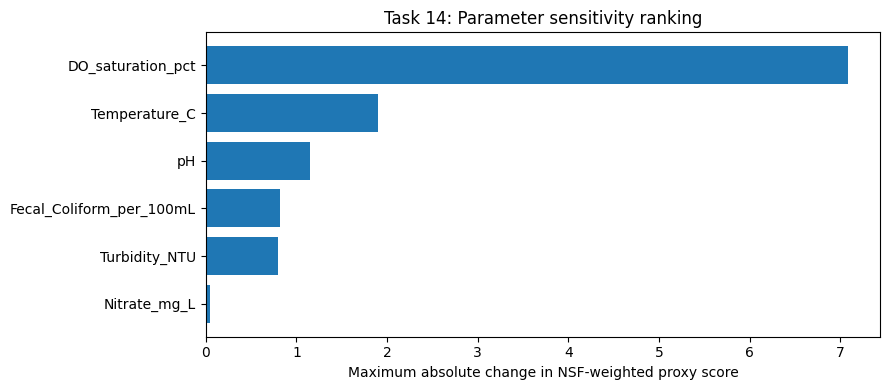

In [11]:
# Tornado-style view: maximum absolute score change per parameter.
tornado=(scenario_table.groupby("Parameter")["WQI change"]
         .apply(lambda s: np.nanmax(np.abs(s))).sort_values())
plt.figure(figsize=(9,max(4,.45*len(tornado))))
plt.barh(tornado.index,tornado.values)
plt.xlabel("Maximum absolute change in NSF-weighted proxy score")
plt.title("Task 14: Parameter sensitivity ranking")
plt.tight_layout(); plt.show()